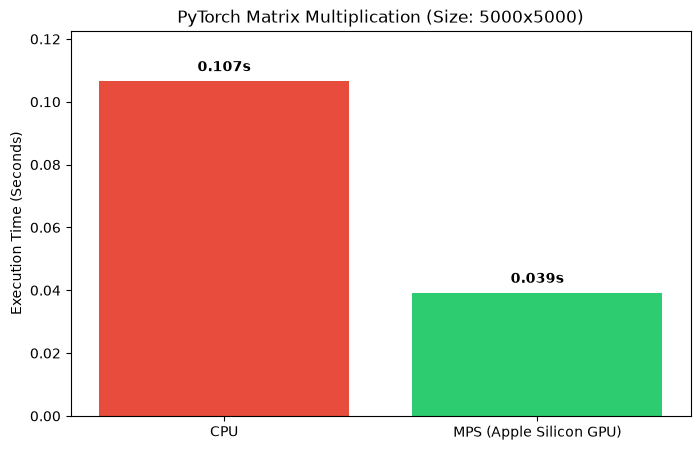


Result: MPS hardware acceleration is 2.7x faster than the CPU.


In [1]:
import torch
import time
import matplotlib.pyplot as plt

# Define matrix size
size = (5000, 5000)

# CPU Test
tensor_cpu = torch.rand(size)
start_cpu = time.time()
_ = torch.matmul(tensor_cpu, tensor_cpu)
time_cpu = time.time() - start_cpu

# MPS Test
device = torch.device("mps")
tensor_mps = torch.rand(size, device=device)

# Warm up run for GPU memory allocation
_ = torch.matmul(tensor_mps, tensor_mps)
torch.mps.synchronize() 

start_mps = time.time()
_ = torch.matmul(tensor_mps, tensor_mps)
torch.mps.synchronize()
time_mps = time.time() - start_mps

# Generate chart
labels = ['CPU', 'MPS (Apple Silicon GPU)']
times = [time_cpu, time_mps]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, times, color=['#e74c3c', '#2ecc71'])
plt.ylabel('Execution Time (Seconds)')
plt.title(f'PyTorch Matrix Multiplication (Size: {size[0]}x{size[1]})')

# Add exact time above each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + (max(times)*0.02), 
             f'{yval:.3f}s', ha='center', va='bottom', fontweight='bold')

plt.ylim(0, max(times) * 1.15) # Add room for labels
plt.show()

print(f"\nResult: MPS hardware acceleration is {time_cpu / time_mps:.1f}x faster than the CPU.")
